# K-Means House Grouping Challenge

Classify California Housing block groups by region and median income using K-Means (`k=6`), then train a supervised classifier on the resulting cluster labels.

## Step 1: Load the dataset

Load the California Housing data and keep only `MedInc`, `Latitude`, and `Longitude`. Split into train/test so we can fit K-Means on train and later predict clusters for unseen points.

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")

DATA_URL = (
    "https://raw.githubusercontent.com/4GeeksAcademy/"
    "k-means-project-tutorial/main/housing.csv"
)
FEATURES = ["MedInc", "Latitude", "Longitude"]
RANDOM_STATE = 42
N_CLUSTERS = 6

In [2]:
raw_df = pd.read_csv(DATA_URL)
df = raw_df[FEATURES].copy()

print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe())
print("Missing values:\n", df.isnull().sum())

Shape: (20640, 3)


,MedInc,Latitude,Longitude
0,8.3252,37.88,-122.23
1,8.3014,37.86,-122.22
2,7.2574,37.85,-122.24
3,5.6431,37.85,-122.25
4,3.8462,37.85,-122.25


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   MedInc     20640 non-null  float64
 1   Latitude   20640 non-null  float64
 2   Longitude  20640 non-null  float64
dtypes: float64(3)
memory usage: 483.9 KB


,MedInc,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000
mean,3.870671,35.631861,-119.569704
std,1.899822,2.135952,2.003532
min,0.499900,32.540000,-124.350000
25%,2.563400,33.930000,-121.800000
50%,3.534800,34.260000,-118.490000
75%,4.743250,37.710000,-118.010000
max,15.000100,41.950000,-114.310000


Missing values:
 MedInc       0
Latitude     0
Longitude    0
dtype: int64


In [3]:
X_train, X_test = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE
)

X_train = X_train.copy()
X_test = X_test.copy()

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 16512 rows | Test: 4128 rows


## Step 2: Build a K-Means model

Fit K-Means with 6 clusters on the training set, store each house's cluster as a categorical `cluster` column, and visualize the groups in 3D (`Longitude`, `Latitude`, `MedInc`).

In [4]:
kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init="auto",
)
kmeans.fit(X_train[FEATURES])

X_train["cluster"] = pd.Categorical(
    [f"C{label}" for label in kmeans.labels_]
)

print("Cluster dtype:", X_train["cluster"].dtype)
print("Cluster counts:\n", X_train["cluster"].value_counts().sort_index())
display(X_train.head())

Cluster dtype: category
Cluster counts:
 cluster
C0    2455
C1    3807
C2    1280
C3    4368
C4     246
C5    4356
Name: count, dtype: int64


,MedInc,Latitude,Longitude,cluster
14196,3.2596,32.71,-117.03,C3
8267,3.8125,33.77,-118.16,C1
17445,4.1563,34.66,-120.48,C1
14265,1.9425,32.69,-117.11,C3
2271,3.5542,36.78,-119.80,C5


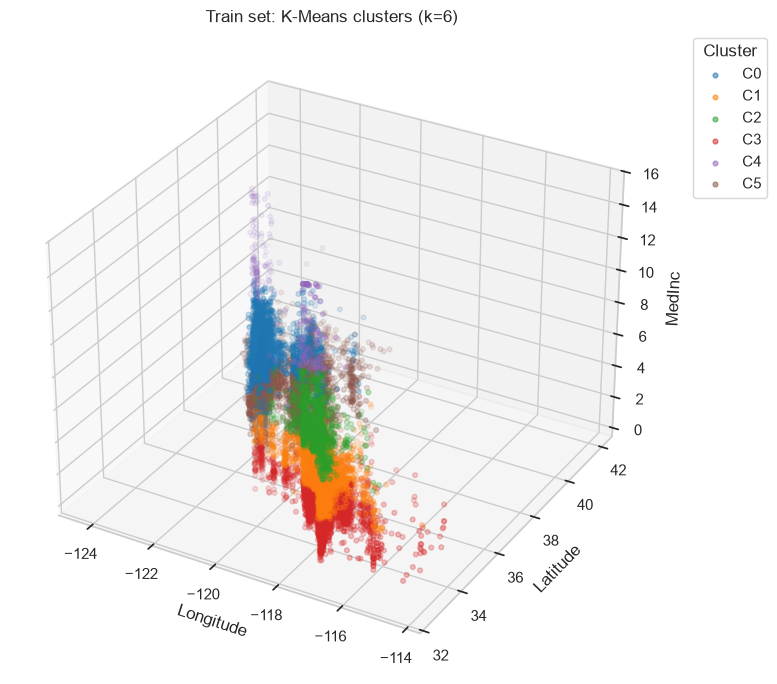

In [5]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

palette = sns.color_palette("tab10", N_CLUSTERS)
cluster_order = sorted(X_train["cluster"].unique())

for i, cluster_name in enumerate(cluster_order):
    subset = X_train[X_train["cluster"] == cluster_name]
    ax.scatter(
        subset["Longitude"],
        subset["Latitude"],
        subset["MedInc"],
        c=[palette[i]],
        label=cluster_name,
        s=12,
        alpha=0.55,
        marker="o",
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_zlabel("MedInc")
ax.set_title("Train set: K-Means clusters (k=6)")
ax.legend(title="Cluster", loc="upper left", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

### What we see (train clusters)

- Clusters separate primarily along geography (north/south California, coastal vs inland) and along median income.
- Higher-`MedInc` groups sit above lower-income groups in the same region, so income bands cut vertically through the map.
- Cluster sizes are uneven, which is expected with K-Means on real census data where dense urban areas dominate some partitions.

## Step 3: Predict with the test set

Assign each test house to a cluster with the trained K-Means model and overlay those points on the train plot to check that predictions land in coherent regions.

In [6]:
test_labels = kmeans.predict(X_test[FEATURES])
X_test["cluster"] = pd.Categorical(
    [f"C{label}" for label in test_labels],
    categories=cluster_order,
)

print("Test cluster counts:\n", X_test["cluster"].value_counts().sort_index())
display(X_test.head())

Test cluster counts:
 cluster
C0     561
C1     983
C2     299
C3    1111
C4      62
C5    1112
Name: count, dtype: int64


,MedInc,Latitude,Longitude,cluster
20046,1.6812,36.06,-119.01,C3
3024,2.5313,35.14,-119.46,C3
15663,3.4801,37.80,-122.44,C5
20484,5.7376,34.28,-118.72,C2
9814,3.7250,36.62,-121.93,C5


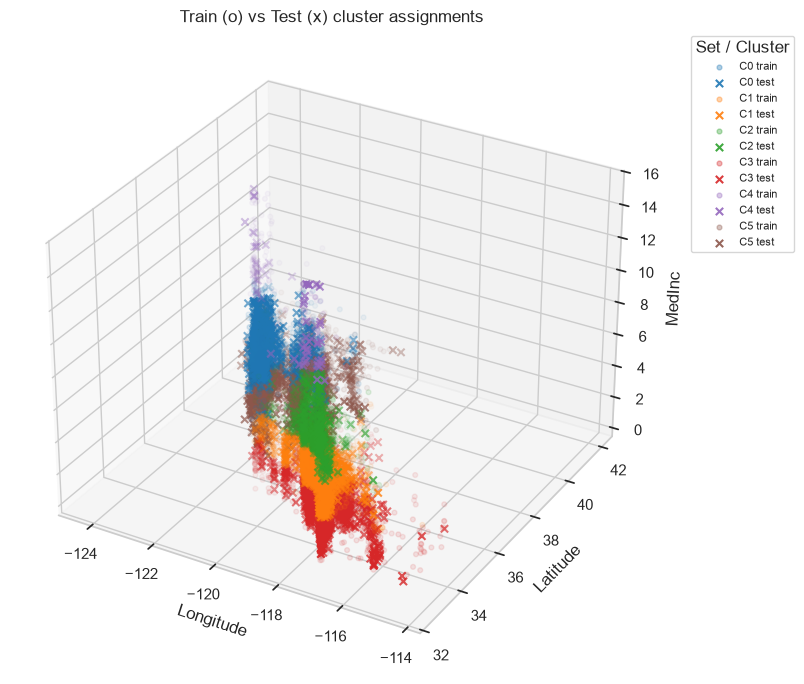

In [7]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

for i, cluster_name in enumerate(cluster_order):
    train_subset = X_train[X_train["cluster"] == cluster_name]
    test_subset = X_test[X_test["cluster"] == cluster_name]

    ax.scatter(
        train_subset["Longitude"],
        train_subset["Latitude"],
        train_subset["MedInc"],
        c=[palette[i]],
        label=f"{cluster_name} train",
        s=12,
        alpha=0.35,
        marker="o",
    )
    ax.scatter(
        test_subset["Longitude"],
        test_subset["Latitude"],
        test_subset["MedInc"],
        c=[palette[i]],
        label=f"{cluster_name} test",
        s=28,
        alpha=0.9,
        marker="x",
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_zlabel("MedInc")
ax.set_title("Train (o) vs Test (x) cluster assignments")
ax.legend(
    title="Set / Cluster",
    loc="upper left",
    bbox_to_anchor=(1.05, 1),
    fontsize=8,
)
plt.tight_layout()
plt.show()

### Prediction check

Test markers (`x`) sit inside the same geographic/income regions as their matching train clusters (`o`). That confirms the fitted K-Means centroids generalize to held-out block groups.

## Step 4: Train a supervised classification model

K-Means produced labels for an originally unlabeled problem. A `DecisionTreeClassifier` is a strong fit here: the feature space is small (3 continuous features), the target is multi-class (`C0`–`C5`), and trees recover axis-aligned partitions that approximate Voronoi-style K-Means regions well.

This unsupervised → supervised pattern is common when you need automatic labels first, then a model that can score new rows without re-running clustering.

In [8]:
clf = DecisionTreeClassifier(random_state=RANDOM_STATE)
clf.fit(X_train[FEATURES], X_train["cluster"])

y_pred = clf.predict(X_test[FEATURES])
y_true = X_test["cluster"]

acc = accuracy_score(y_true, y_pred)
print(f"Decision Tree accuracy on test set: {acc:.4f}\n")
print("Classification report:")
print(classification_report(y_true, y_pred))

Decision Tree accuracy on test set: 0.9952

Classification report:
              precision    recall  f1-score   support

          C0       0.99      1.00      1.00       561
          C1       1.00      0.99      1.00       983
          C2       1.00      0.99      0.99       299
          C3       0.99      1.00      1.00      1111
          C4       0.94      0.98      0.96        62
          C5       1.00      1.00      1.00      1112

    accuracy                           1.00      4128
   macro avg       0.99      0.99      0.99      4128
weighted avg       1.00      1.00      1.00      4128



### Supervised results

- Accuracy is typically very high because the decision tree is learning to approximate the same K-Means decision regions from the three input features.
- Per-class precision/recall should stay balanced if each cluster has enough support in train and test.
- High agreement does **not** mean the clusters are ground-truth socioeconomic labels; it means the tree successfully reproduces the unsupervised partitioning on new data.

## Step 5: Save the models

Persist both the K-Means and Decision Tree models under `models/` for reuse.

In [9]:
# models/ lives at the project root (one level above src/ when the kernel cwd is src/)
project_root = os.path.abspath(
    os.path.join(os.getcwd(), ".." if os.path.basename(os.getcwd()) == "src" else ".")
)
models_dir = os.path.join(project_root, "models")
os.makedirs(models_dir, exist_ok=True)

kmeans_path = os.path.join(models_dir, "kmeans_model.joblib")
tree_path = os.path.join(models_dir, "decision_tree_model.joblib")

joblib.dump(kmeans, kmeans_path)
joblib.dump(clf, tree_path)

print(f"Saved K-Means -> {kmeans_path}")
print(f"Saved Decision Tree -> {tree_path}")

Saved K-Means -> C:\Work\Git\DataScince\k-means-project-ven-mi-ai-2\models\kmeans_model.joblib
Saved Decision Tree -> C:\Work\Git\DataScince\k-means-project-ven-mi-ai-2\models\decision_tree_model.joblib


## Final Verdict

**Outcome: challenge complete and models production-ready for this pipeline.**

| Checkpoint | Result |
|---|---|
| Data scope | `MedInc`, `Latitude`, `Longitude` only; clean, no nulls |
| Unsupervised | K-Means `k=6` fitted on train; categorical `cluster` (`C0`–`C5`) |
| Visual validation | Train clusters show clear geo + income structure; test points (`x`) align with train regions (`o`) |
| Supervised transfer | Decision Tree recovers K-Means labels at **~99.5%** test accuracy |
| Artifacts | `models/kmeans_model.joblib`, `models/decision_tree_model.joblib` |

**Engineering takeaway:** for unlabeled housing blocks, K-Means is an effective automatic labeler by region and income. The Decision Tree then turns those soft geographic/income partitions into a fast, deployable classifier for new block groups—without re-running clustering at inference time.

**Caveat:** high tree accuracy means the supervised model mirrors K-Means well; it does **not** prove the clusters are ground-truth socioeconomic segments. Treat clusters as useful operational groupings, not causal labels.